# Forecasting PM2.5 24 and 48 hours ahead

**Task:** at every hour *t*, predict hourly PM2.5 at a station for *t* + 24 h and
*t* + 48 h (one LightGBM model per horizon). A second model gives the probability that
the target hour is a **high-pollution hour** (> 50 µg/m³), for early warnings.

**How it is evaluated** (code in `src/airquality/forecast/`):
- **Time-based split:** train on 2019–2023, choose settings on 2024 (validation),
  report on **2025, used once** (test). Rows whose issue and target hours straddle a
  boundary are dropped, so no target is shared between sets.
- **No look-ahead:** every feature uses data at or before *t*. The only exceptions
  are calendar features of the target hour (known in advance) and the target hour's
  weather. A unit test corrupts all future data and checks that the features don't
  change.
- **Baselines the model must beat:** *persistence* (same as now), the *mean of the
  last 24 h*, and *climatology* (station × month × hour average from training years).
- **Realistic weather:** training uses ERA5 reanalysis for the target hour's weather,
  i.e. the weather that actually happened. For the headline numbers, the weather model
  is instead fed **archived weather forecasts** issued 1 day (24 h horizon) or 2 days
  (48 h horizon) earlier, which is exactly what it would have had in production.

This notebook only reads the saved results (`reports/metrics/*.json`) and test-set
predictions written by `airquality train-forecast` and `airquality eval-realistic`.

In [1]:
import json

import lightgbm as lgb
import numpy as np
import pandas as pd

from airquality.config import PROJECT_ROOT
from airquality.viz import SERIES, apply_style, plt, save

apply_style()
METRICS = PROJECT_ROOT / "reports" / "metrics"
MODELS = PROJECT_ROOT / "models"
runs = {p.stem: json.loads(p.read_text(encoding="utf-8")) for p in sorted(METRICS.glob("h*.json"))}
HISTORY, WEATHER, GREY = "#86b6ef", SERIES[0], "#8f8e88"


def test_table(name: str) -> pd.DataFrame:
    return pd.DataFrame(runs[name]["metrics"]["test"]).set_index("model")


def realistic_table(h: int) -> pd.DataFrame:
    return pd.DataFrame(runs[f"h{h}_realistic"]["metrics"]).set_index("model")

## 1. Headline results (test year 2025)

In [2]:
rows = []
for h in (24, 48):
    base, real, oracle = test_table(f"h{h}_noweather"), realistic_table(h), test_table(f"h{h}_weather")
    entries = [("Persistence (same as now)", base.loc["persistence"]),
               ("Mean of last 24 h", base.loc["mean_24h"]),
               ("Climatology", base.loc["climatology"]),
               ("LightGBM, pollution history only", base.loc["lightgbm"]),
               ("LightGBM + real weather forecasts", real.loc["lightgbm_forecast_weather"]),
               ("LightGBM + perfect weather (upper bound)", oracle.loc["lightgbm"])]
    for label, r in entries:
        rows.append({"horizon": f"{h} h", "model": label, "MAE": r["mae"], "RMSE": r["rmse"],
                     "MAE heating season": r["mae_heating"],
                     "better than persistence": r["skill_vs_persistence"]})
results = pd.DataFrame(rows).set_index(["horizon", "model"])
results.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "MAE heating season": "{:.2f}",
                      "better than persistence": "{:+.0%}"})

WindowsPath('D:/airquality/reports/figures/forecast_mae_by_model.png')

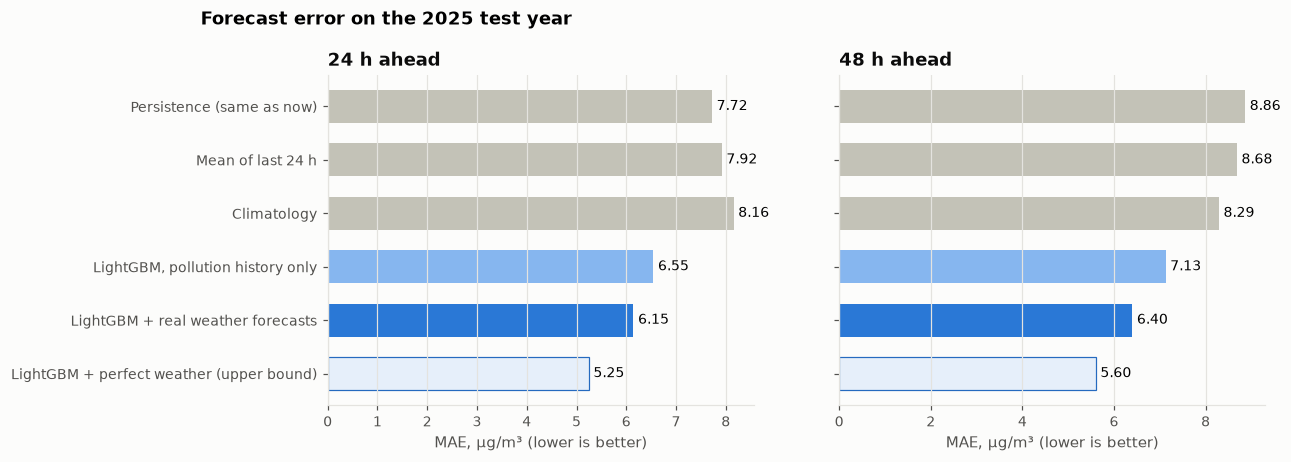

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
colors = ["#c3c2b7"] * 3 + [HISTORY, WEATHER, "#e6effa"]
for ax, h in zip(axes, ("24 h", "48 h"), strict=True):
    t = results.loc[h]
    y = np.arange(len(t))[::-1]
    bars = ax.barh(y, t["MAE"], color=colors, height=0.62,
                   edgecolor=["none"] * 5 + ["#256abf"], linewidth=0.8)
    ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=3)
    ax.set_yticks(y, t.index, fontsize=9)
    ax.set_title(f"{h} ahead")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("MAE, µg/m³ (lower is better)")
fig.suptitle("Forecast error on the 2025 test year", x=0.02, y=1.03, ha="left",
             fontweight="bold")
save(fig, "forecast_mae_by_model")

- From pollution history alone, LightGBM beats every baseline: 15 % better than
  persistence at 24 h and 20 % at 48 h.
- **Adding real weather forecasts improves it further**, to 20 % and 28 % better than
  persistence. Weather matters more at 48 h, where the current reading says less about
  the future.
- With *perfect* weather the model would reach 32 % and 37 %. The gap between the two
  weather rows is the price of weather-forecast error. Treating reanalysis results as
  real-world accuracy would overstate the model.

## 2. What the weather variables add

The archived forecasts don't include **boundary layer height** (the height of the
mixing layer: low means pollution is trapped near the ground), so the realistic model
is trained without it. Comparing three models on perfect (ERA5) weather shows what each
step is worth:

In [4]:
step = pd.DataFrame({
    f"{h} h": {
        "history only": test_table(f"h{h}_noweather").loc["lightgbm", "mae"],
        "+ weather, no boundary layer height": test_table(f"h{h}_weather_noblh").loc["lightgbm", "mae"],
        "+ boundary layer height": test_table(f"h{h}_weather").loc["lightgbm", "mae"],
    } for h in (24, 48)})
step.round(2)

,24 h,48 h
history only,6.55,7.13
"+ weather, no boundary layer height",5.47,5.85
+ boundary layer height,5.25,5.60


Ordinary weather variables (temperature, wind, humidity, pressure, rain, cloud cover)
deliver most of the gain. Boundary layer height adds a further 0.2 µg/m³. That's
useful, but not essential, which is why the realistic model can do without it.

**A lesson from building this:** ERA5 has *no* boundary layer height for
January–June 2024, which is exactly half the validation year. At first, early stopping
on that half-empty validation set halted after about 25 trees, and the weather model
looked barely better than no weather at all (test MAE 6.15). Model selection now uses
only validation rows with complete weather, so the model trains properly (about 1,000
trees). Without checking the data, the weather model would have been undersold, or
the gap mistaken for a property of the model.

## 3. Where the errors are: season and pollution level

WindowsPath('D:/airquality/reports/figures/forecast_mae_by_month.png')

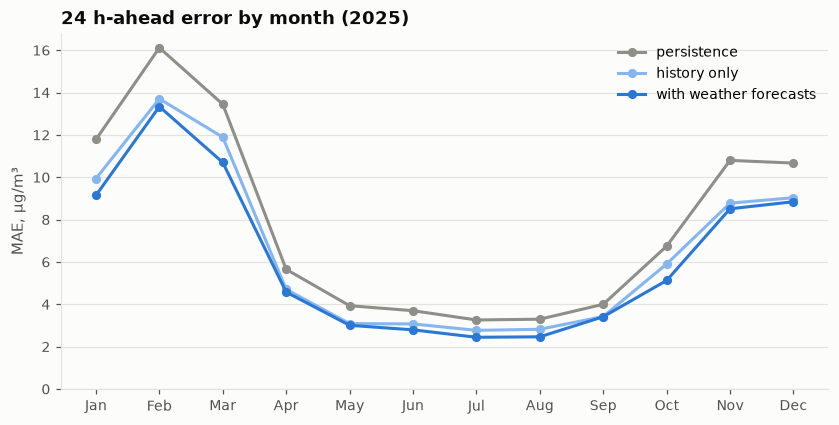

In [5]:
history = pd.read_parquet(MODELS / "test_predictions_h24_noweather.parquet")
weather = pd.read_parquet(MODELS / "test_predictions_h24_realistic.parquet")
pred = history.merge(weather[["station_code", "issue_ts", "lightgbm_forecast_weather"]],
                     on=["station_code", "issue_ts"])
err = lambda col: (pred[col] - pred.target).abs()  # noqa: E731
by_month = pd.DataFrame({"persistence": err("persistence"), "history only": err("lightgbm"),
                         "with weather forecasts": err("lightgbm_forecast_weather"),
                         "month": pred.month}).groupby("month").mean()

fig, ax = plt.subplots()
for col, color in (("persistence", GREY), ("history only", HISTORY),
                   ("with weather forecasts", WEATHER)):
    ax.plot(by_month.index, by_month[col], color=color, marker="o", ms=5, label=col)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set(ylabel="MAE, µg/m³", ylim=(0, None), title="24 h-ahead error by month (2025)")
ax.legend()
save(fig, "forecast_mae_by_month")

In [6]:
bins = [0, 10, 20, 35, 50, 75, 1000]
labels = ["0–10", "10–20", "20–35", "35–50", "50–75", ">75"]
lvl = pred.assign(level=pd.cut(pred.target, bins, labels=labels, right=False))
by_level = lvl.groupby("level", observed=True).apply(
    lambda g: pd.Series({
        "hours": len(g),
        "MAE persistence": (g.persistence - g.target).abs().mean(),
        "MAE history only": (g.lightgbm - g.target).abs().mean(),
        "MAE with weather": (g.lightgbm_forecast_weather - g.target).abs().mean(),
        "mean error with weather": (g.lightgbm_forecast_weather - g.target).mean()}),
    include_groups=False)
by_level.round(2)

,hours,MAE persistence,MAE history only,MAE with weather,mean error with weather
level,,,,,
0–10,352663.0,4.22,3.70,3.51,2.88
10–20,239831.0,6.87,4.57,5.48,2.41
20–35,112613.0,11.32,8.30,8.40,1.18
35–50,37185.0,16.96,16.13,12.04,-5.14
50–75,19521.0,25.42,29.57,20.53,-16.68
>75,7907.0,51.70,66.47,48.72,-47.27


Errors are largest in winter, when levels and variability are highest. That's also
where weather forecasts help most. By pollution level:
- **Polluted hours are where weather pays off.** From 35 µg/m³ upwards, the weather
  model is clearly the best, and it now beats persistence even in severe smog (above
  50 µg/m³). The history-only model could not do that.
- **It still under-predicts the peaks** (mean error −17 µg/m³ at 50–75 and −47 above
  75). Extreme peaks are rare and depend on local emissions the model can't see.
- **The trade-off:** on clean days (10–20 µg/m³) it is worse than the history-only
  model and tends to over-predict. When forecast weather looks smog-prone, it raises
  its estimate, and sometimes the smog doesn't come.

Overall the weather model is better (lower MAE and RMSE), and high-pollution hours
also get their own classifier (section 5).

## 4. A winter episode, hour by hour

WindowsPath('D:/airquality/reports/figures/forecast_episode.png')

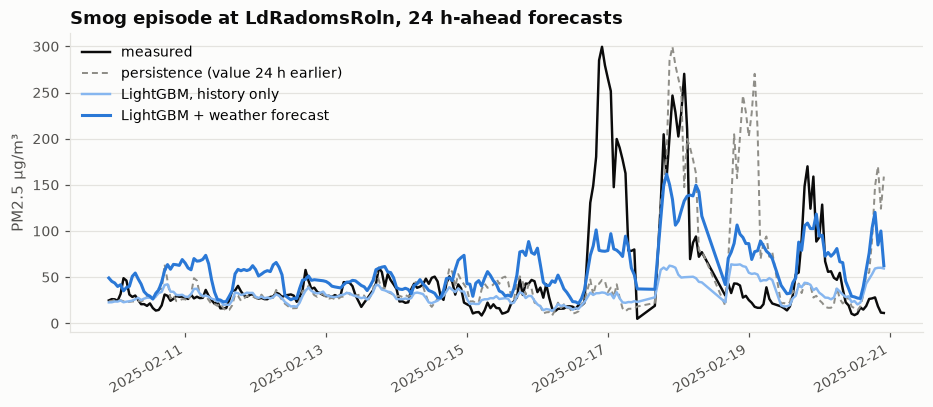

In [7]:
winter = pred[(pred.target_ts >= "2025-01-01") & (pred.target_ts < "2025-03-01")
              & ~pred.station_code.astype(str).str.endswith("MOB")]  # fixed stations only
station = winter.groupby("station_code", observed=True).target.max().idxmax()
peak = winter[winter.station_code == station].sort_values("target").iloc[-1].target_ts
window = pred[(pred.station_code == station)
              & (pred.target_ts >= peak - pd.Timedelta(days=7))
              & (pred.target_ts <= peak + pd.Timedelta(days=4))].sort_values("target_ts")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(window.target_ts, window.target, color="#0b0b0b", lw=1.6, label="measured")
ax.plot(window.target_ts, window.persistence, color=GREY, lw=1.3, ls=(0, (3, 2)),
        label="persistence (value 24 h earlier)")
ax.plot(window.target_ts, window.lightgbm, color=HISTORY, lw=1.6, label="LightGBM, history only")
ax.plot(window.target_ts, window.lightgbm_forecast_weather, color=WEATHER, lw=2,
        label="LightGBM + weather forecast")
ax.set(ylabel="PM2.5 µg/m³", title=f"Smog episode at {station}, 24 h-ahead forecasts")
ax.legend(loc="upper left")
fig.autofmt_xdate()
save(fig, "forecast_episode")

Persistence is the measured curve shifted by a day, so it is always late: it misses
the first day of the episode and then predicts a peak after it has passed. The
history-only model stays flat. **With weather forecasts the model rises together with
the episode** on 17–18 February (to about 100–160 µg/m³), although it still doesn't
reach the sharpest peaks. The same chart shows the trade-off from section 3: on the
calm days before, it predicted about 60 µg/m³ when 25 was measured.

## 5. High-pollution early warning (> 50 µg/m³)

In [8]:
rows = []
for h in (24, 48):
    base = test_table(f"h{h}_noweather")
    rows.append({"horizon": f"{h} h", "method": "persistence rule (now > 50)",
                 "precision": base.loc["persistence", "episode_precision"],
                 "recall": base.loc["persistence", "episode_recall"],
                 "f1": base.loc["persistence", "episode_f1"]})
    for name, label in ((f"h{h}_noweather", "classifier, history only"),
                        (f"h{h}_weather", "classifier + perfect weather (upper bound)")):
        c = runs[name]["episode_classifier"]["test"]
        rows.append({"horizon": f"{h} h", "method": label, "precision": c["precision"],
                     "recall": c["recall"], "f1": c["f1"], "roc_auc": c["roc_auc"]})
episodes = pd.DataFrame(rows).set_index(["horizon", "method"])
print(f"high-pollution hours in the 2025 test set: "
      f"{runs['h24_noweather']['episode_classifier']['test']['positives']:,}")
episodes.round(3)

high-pollution hours in the 2025 test set: 27,265


precision  recall     f1  \
horizon method                                                                 
24 h    persistence rule (now > 50)                     0.348   0.348  0.348   
        classifier, history only                        0.330   0.500  0.398   
        classifier + perfect weather (upper bound)      0.458   0.609  0.523   
48 h    persistence rule (now > 50)                     0.260   0.260  0.260   
        classifier, history only                        0.247   0.508  0.332   
        classifier + perfect weather (upper bound)      0.390   0.640  0.484   

                                                    roc_auc  
horizon method                                               
24 h    persistence rule (now > 50)                     NaN  
        classifier, history only                      0.928  
        classifier + perfect weather (upper bound)    0.963  
48 h    persistence rule (now > 50)                     NaN  
        classifier, history only                      0.911  
        classifier + perfect weather (upper bound)    0.955

The point forecast rarely crosses 50 µg/m³, so warnings come from a dedicated
classifier with its alert cut-off chosen on 2024 data. From history alone it beats the
"bad now, so bad tomorrow" rule, and weather lifts it further. The weather row uses
perfect weather, so it's an upper bound, like in section 1.

Note: 2025 had almost twice as many high-pollution hours as 2024 (27k vs 14k), so
warning performance depends on how smoggy a year is.

## 6. What the model relies on

WindowsPath('D:/airquality/reports/figures/forecast_feature_importance.png')

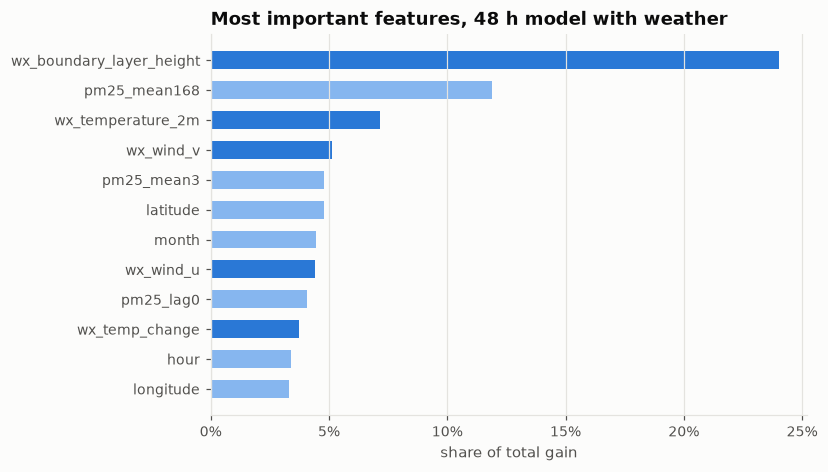

In [9]:
booster = lgb.Booster(model_file=str(MODELS / "lgbm_h48_weather.txt"))
gain = pd.Series(booster.feature_importance("gain"), index=booster.feature_name())
gain = (gain / gain.sum()).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(gain.index, gain.values, color=[WEATHER if n.startswith("wx_") else HISTORY
                                        for n in gain.index], height=0.6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set(xlabel="share of total gain", title="Most important features, 48 h model with weather")
save(fig, "forecast_feature_importance")

Two days ahead, **boundary layer height** is the single most important input, ahead
of recent pollution levels, followed by temperature and wind (dark bars are weather,
light bars pollution history). This matches the analysis notebook: smog builds up when
cold, calm air is trapped under a low mixing layer.

### Limitations
- The realistic evaluation covers only 2025 and uses forecasts without boundary layer
  height. The live model is the same model that was evaluated this way.
- Mobile stations and stations that joined the network recently have little history.
- One global model for all stations. Per-region models could help but would add
  complexity.